<a href="https://colab.research.google.com/github/TudorVilcu/Tudor-Vilcu---Data-Science-and-Gen-AI-submission-/blob/main/7_01_Exploratory_Data_Analysis_Salary_Student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1xqQczl0FG-qtNA2_WQYuWePW9oU8irqJ)

# 2.05 Exploratory Data Analysis (EDA)
In this exercise, you will explore a salary dataset (`EDA-DP.csv`) from the Week 7 Seminar Resources on myWBS. Work through the tasks in order. The setup cell below imports the libraries and allows you to upload the dataset.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from google.colab import files
upload = files.upload()

Saving EDA-DP.csv to EDA-DP (1).csv


**Task 1 — Load the data.** Read `EDA-DP.csv` into a pandas DataFrame and display the first few rows.

In [2]:
df = pd.read_csv('EDA-DP.csv'); df.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2024,SE,FT,AI Engineer,202730,USD,202730,US,0,US,M
1,2024,SE,FT,AI Engineer,92118,USD,92118,US,0,US,M
2,2024,SE,FT,Data Engineer,130500,USD,130500,US,0,US,M
3,2024,SE,FT,Data Engineer,96000,USD,96000,US,0,US,M
4,2024,SE,FT,Machine Learning Engineer,190000,USD,190000,US,0,US,M


**Task 2 — Dataset size.** Find the number of rows and columns in the dataset.

In [3]:
df.shape

(16534, 11)

**Task 3 — Dataset structure.** Inspect the column names, data types, and number of non-missing values.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16534 entries, 0 to 16533
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           16534 non-null  int64 
 1   experience_level    16534 non-null  object
 2   employment_type     16534 non-null  object
 3   job_title           16534 non-null  object
 4   salary              16534 non-null  int64 
 5   salary_currency     16534 non-null  object
 6   salary_in_usd       16534 non-null  int64 
 7   employee_residence  16534 non-null  object
 8   remote_ratio        16534 non-null  int64 
 9   company_location    16534 non-null  object
 10  company_size        16534 non-null  object
dtypes: int64(4), object(7)
memory usage: 1.4+ MB


**Task 4 — Missing data.** Check how many missing values there are in each column.

In [5]:
df.isnull().sum()

,0
work_year,0
experience_level,0
employment_type,0
job_title,0
salary,0
salary_currency,0
salary_in_usd,0
employee_residence,0
remote_ratio,0
company_location,0


**Task 5 — Missing-data percentages.** Calculate the percentage of missing values for each column. Think about how you would handle missing data if you found any.

In [6]:
# Percent of data which is not available
df.isnull().sum()/len('EDA-DP.csv') * 100

,0
work_year,0.0
experience_level,0.0
employment_type,0.0
job_title,0.0
salary,0.0
salary_currency,0.0
salary_in_usd,0.0
employee_residence,0.0
remote_ratio,0.0
company_location,0.0


**Task 6 — Duplicates.** Find how many rows are exact duplicates and how many are not. Would identical records necessarily be errors in this dataset?

In [7]:
df.duplicated().value_counts()

,count
False,10113
True,6421


**Task 7 — Summary statistics.** Produce descriptive statistics for the numerical columns. What do the distributions tell you? Note that `salary` may use different currencies, whereas `salary_in_usd` is comparable across records.

In [8]:
df.describe()


,work_year,salary,salary_in_usd,remote_ratio
count,16534.000000,1.653400e+04,16534.000000,16534.000000
mean,2023.226866,1.637270e+05,149686.777973,32.003750
std,0.713558,3.402057e+05,68505.293156,46.245158
min,2020.000000,1.400000e+04,15000.000000,0.000000
25%,2023.000000,1.017630e+05,101125.000000,0.000000
50%,2023.000000,1.422000e+05,141300.000000,0.000000
75%,2024.000000,1.872000e+05,185900.000000,100.000000
max,2024.000000,3.040000e+07,800000.000000,100.000000


### Visualising the Data

**Task 8 — Bar chart.** Create a bar chart comparing the **average salary in USD** across experience levels (`EN`, `MI`, `SE`, `EX`). Add clear axis labels and a title. Which group has the highest average?

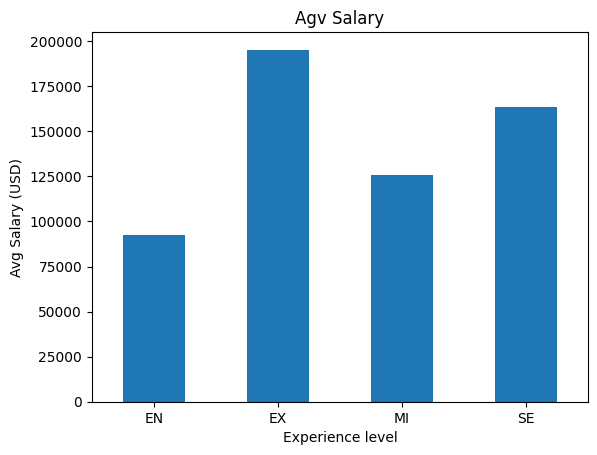

In [9]:

df.groupby('experience_level')['salary_in_usd'].mean().plot(kind='bar')
plt.xlabel('Experience level')
plt.ylabel('Avg Salary (USD)')
plt.title('Agv Salary')
plt.xticks(rotation=0)
plt.show()

**Task 9 — Scatter plot.** Make a scatter plot of `work_year` against `salary_in_usd`. Label the axes. What patterns do you notice? Are any points difficult to distinguish because they overlap?

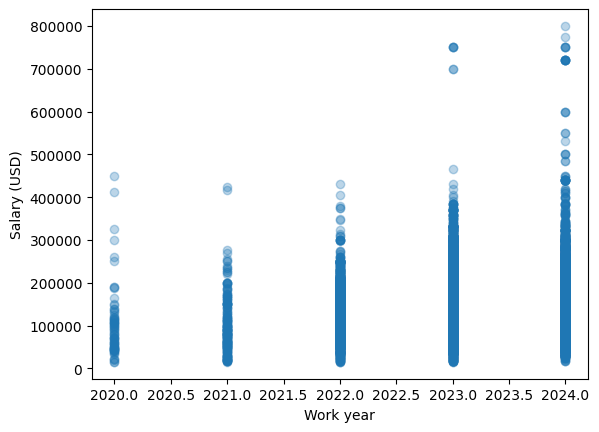

In [10]:
plt.scatter(df['work_year'], df['salary_in_usd'], alpha=0.3)
plt.xlabel('Work year'); plt.ylabel('Salary (USD)'); plt.show()

**Task 10 — Distribution.** Plot the distribution of `salary_in_usd`. Does it look approximately normal, skewed, or something else? Are there extreme values?

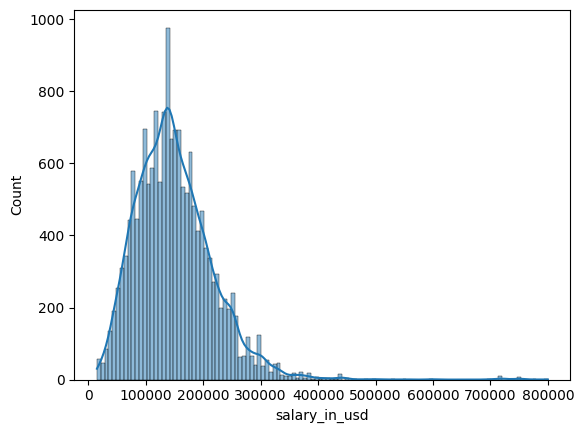

In [11]:
sns.histplot(df['salary_in_usd'], kde=True); plt.show()


**Task 11 — Pairwise relationships.** Visualize pairwise relationships among `salary_in_usd`, `work_year`, and `remote_ratio`, including distributions of the individual variables.

Try to compare the variables in one combined visualization. What relationships or patterns do you notice?

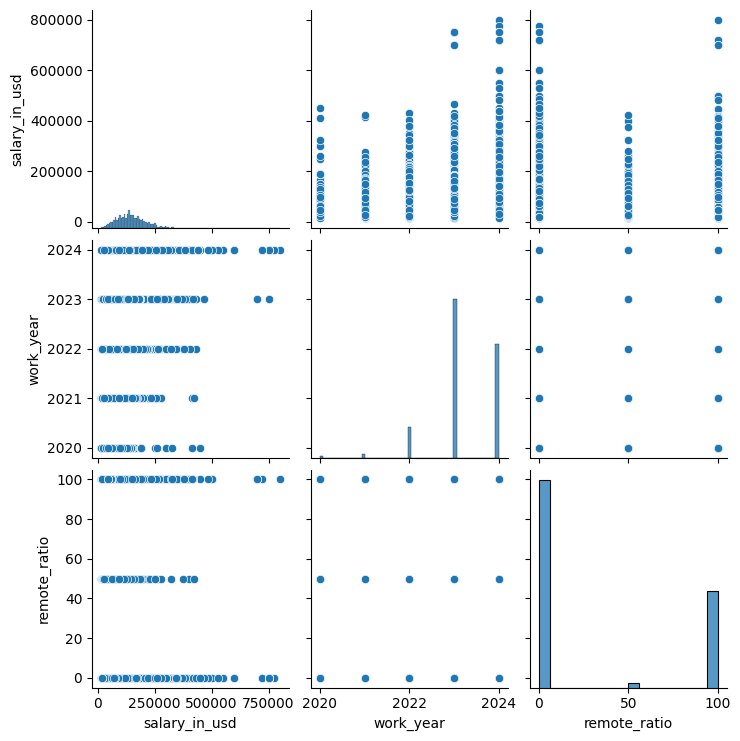

In [12]:
sns.pairplot(df[['salary_in_usd', 'work_year', 'remote_ratio']]); plt.show()



**Task 12 — Remove a column.** Remove the original-currency `salary` column while retaining `salary_in_usd`, then inspect the updated DataFrame. Why might you choose to keep one salary column rather than both?

In [13]:
df = df.drop(columns=['salary']); df.head()


,work_year,experience_level,employment_type,job_title,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2024,SE,FT,AI Engineer,USD,202730,US,0,US,M
1,2024,SE,FT,AI Engineer,USD,92118,US,0,US,M
2,2024,SE,FT,Data Engineer,USD,130500,US,0,US,M
3,2024,SE,FT,Data Engineer,USD,96000,US,0,US,M
4,2024,SE,FT,Machine Learning Engineer,USD,190000,US,0,US,M


**Reflection.** What have you learned about the salary dataset? Which additional checks or visualizations would be useful before building a machine learning model?

Well done!